# Predictive Maintenance
## Turbofan Engine Degradation Simulation Data Set

### Plugins

In [ ]:
!python --version

Python 3.13.18


In [ ]:
!pip install -q streamlit joblib catboost

Library versions used in this project

In [ ]:
!pip freeze | grep -iE "streamlit|scikit-learn|xgboost|lightgbm|catboost|pandas|numpy|joblib|matplotlib"

catboost==1.2.10
geopandas==1.2.0
joblib==1.6.0
lightgbm==4.6.0
matplotlib==3.10.0
matplotlib-inline==0.2.2
matplotlib-venn==1.1.2
numpy==2.4.6
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
scikit-learn==1.6.1
sklearn-pandas==2.2.0
streamlit==1.67.0
xgboost==3.4.1


In [ ]:
import os
import shap
import joblib
import warnings
import time as t
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.model_selection import cross_val_score, GridSearchCV, cross_validate, GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler, FunctionTransformer, OrdinalEncoder, StandardScaler
# XGBoost
from xgboost import XGBClassifier, XGBRegressor
# LightGBM
from lightgbm import LGBMClassifier, LGBMRegressor
# CatBoost
from catboost import CatBoostClassifier, CatBoostRegressor

 Ignore unnecessary outputs

In [ ]:
warnings.filterwarnings("ignore")

### Dataset Loading

In [ ]:
# Download latest version
path = kagglehub.dataset_download("bishals098/nasa-turbofan-engine-degradation-simulation")
# Define column names as per the dataset structure
cols = ["unit", "cycle", "setting1", "setting2", "setting3"] + [f"s{i}" for i in range(1, 22)]

100%|██████████| 12.3M/12.3M [00:00<00:00, 124MB/s]

Extracting files...


### Data Exploration

In [ ]:
def find(name):
    for root, _, files in __import__("os").walk(path):
        if name in files:
            return f"{root}/{name}"

specify the dataset version being used. In this project only FD001 & FD003 have been explored.

In [ ]:
file_v = "FD001"

In [ ]:
# Validation check to ensure file_v is valid
valid_files = ["FD001", "FD002", "FD003", "FD004"]

if file_v in valid_files:
    train_file = f"train_{file_v}.txt"
    test_file  = f"test_{file_v}.txt"
    rul_file   = f"RUL_{file_v}.txt"
else:
    raise ValueError(f"Invalid file version: {file_v}. Expected one of {valid_files}")

In [ ]:
df = pd.read_csv(find(train_file), sep=r"\s+", header=None, names=cols)
test = pd.read_csv(find(test_file), sep=r"\s+", header=None, names=cols)
true_rul = pd.read_csv(find(rul_file), header=None, names=["RUL"])["RUL"].values

In [ ]:
# Peek at the top rows
df.head()

,unit,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [ ]:
test.head()

,unit,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [ ]:
print("Data Type:", true_rul.dtype)
print("First 5 values:", true_rul[:5])

Data Type: int64
First 5 values: [112  98  69  82  91]


In [ ]:
print("Shape:", df.shape)

Shape: (20631, 26)


In [ ]:
print("\nData types & non-null counts:")
print(df.info())


Data types & non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   unit      20631 non-null  int64  
 1   cycle     20631 non-null  int64  
 2   setting1  20631 non-null  float64
 3   setting2  20631 non-null  float64
 4   setting3  20631 non-null  float64
 5   s1        20631 non-null  float64
 6   s2        20631 non-null  float64
 7   s3        20631 non-null  float64
 8   s4        20631 non-null  float64
 9   s5        20631 non-null  float64
 10  s6        20631 non-null  float64
 11  s7        20631 non-null  float64
 12  s8        20631 non-null  float64
 13  s9        20631 non-null  float64
 14  s10       20631 non-null  float64
 15  s11       20631 non-null  float64
 16  s12       20631 non-null  float64
 17  s13       20631 non-null  float64
 18  s14       20631 non-null  float64
 19  s15       20631 non-null  float64
 2

In [ ]:
print("\nSummary statistics (first few columns):")
print(df.describe().T.head(10))


Summary statistics (first few columns):
            count         mean           std        min        25%      50%  \
unit      20631.0    51.506568  2.922763e+01     1.0000    26.0000    52.00   
cycle     20631.0   108.807862  6.888099e+01     1.0000    52.0000   104.00   
setting1  20631.0    -0.000009  2.187313e-03    -0.0087    -0.0015     0.00   
setting2  20631.0     0.000002  2.930621e-04    -0.0006    -0.0002     0.00   
setting3  20631.0   100.000000  0.000000e+00   100.0000   100.0000   100.00   
s1        20631.0   518.670000  6.537152e-11   518.6700   518.6700   518.67   
s2        20631.0   642.680934  5.000533e-01   641.2100   642.3250   642.64   
s3        20631.0  1590.523119  6.131150e+00  1571.0400  1586.2600  1590.10   
s4        20631.0  1408.933782  9.000605e+00  1382.2500  1402.3600  1408.04   
s5        20631.0    14.620000  3.394700e-12    14.6200    14.6200    14.62   

                75%        max  
unit        77.0000   100.0000  
cycle      156.0000   3

Check for duplicate or missing

In [ ]:
# Check duplicate (same unit, same cycle)
dup = df.duplicated(subset=["unit", "cycle"]).sum()
print("Duplicate (unit,cycle) rows:", dup)

Duplicate (unit,cycle) rows: 0


In [ ]:
# Count missing in each column
na_counts = df.isna().sum()
print("\nMissing counts (top 10):")
print(na_counts.sort_values(ascending=False))


Missing counts (top 10):
unit        0
cycle       0
setting1    0
setting2    0
setting3    0
s1          0
s2          0
s3          0
s4          0
s5          0
s6          0
s7          0
s8          0
s9          0
s10         0
s11         0
s12         0
s13         0
s14         0
s15         0
s16         0
s17         0
s18         0
s19         0
s20         0
s21         0
dtype: int64


Number of Engines in the dataset

In [ ]:
df['unit'].nunique()

100

### Final cycle of each Engine
Displays Skewness

Number of engines: 100
Cycle count statistics:
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


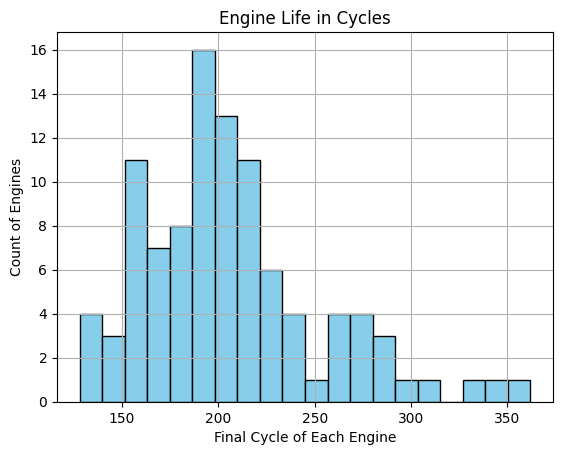

In [ ]:
# Compute max cycle attained by each engine
cycles = df.groupby("unit")["cycle"].max()
print("Number of engines:", cycles.count())
print("Cycle count statistics:")
print(cycles.describe())

# Plot histogram
cycles.plot(kind='hist', bins=20, color='skyblue', edgecolor='black', title="Engine Life in Cycles", grid=True)
plt.xlabel("Final Cycle of Each Engine")
plt.ylabel("Count of Engines")
plt.show()

### Sensor Variance

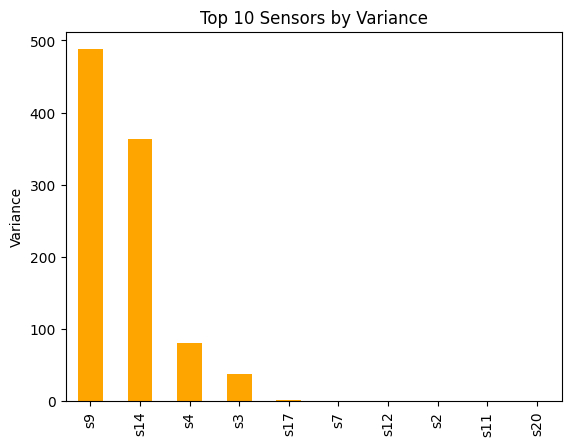

In [ ]:
# Extract sensor columns
sensor_cols = df.iloc[:, 5:]

# Variance per sensor
var_series = sensor_cols.var().sort_values(ascending=False)

# Bar plot for sensors with highest variance
var_series.head(10).plot(kind='bar', color='orange', title="Top 10 Sensors by Variance")
plt.ylabel("Variance")
plt.show()

### Trend

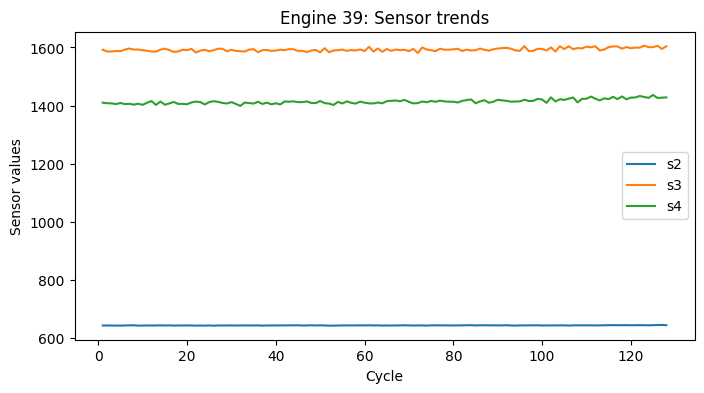

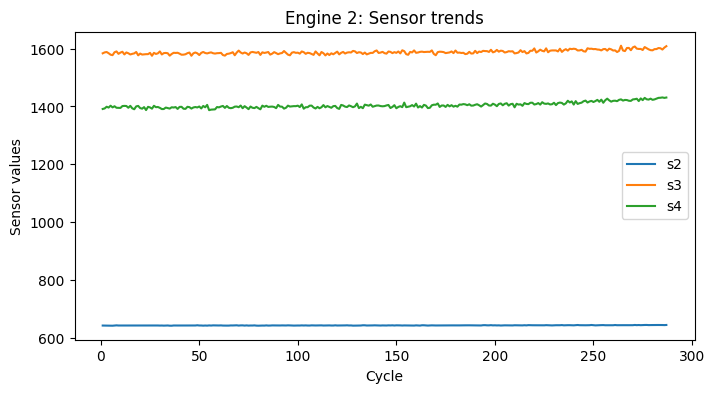

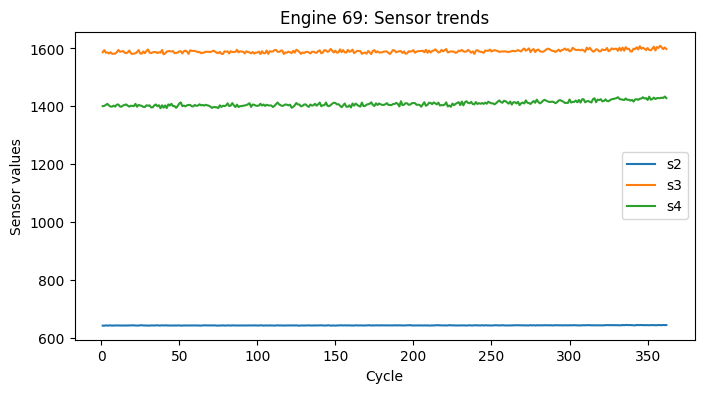

In [ ]:
# Pick a few engine IDs (units)
sample_units = [cycles.idxmin(), 2, cycles.idxmax()]

for u in sample_units:
    sub = df[df["unit"] == u].set_index("cycle")
    sub.iloc[:, 5:8].plot(figsize=(8,4), title=f"Engine {u}: Sensor trends")
    plt.xlabel("Cycle")
    plt.ylabel("Sensor values")
    plt.show()

### Correlation

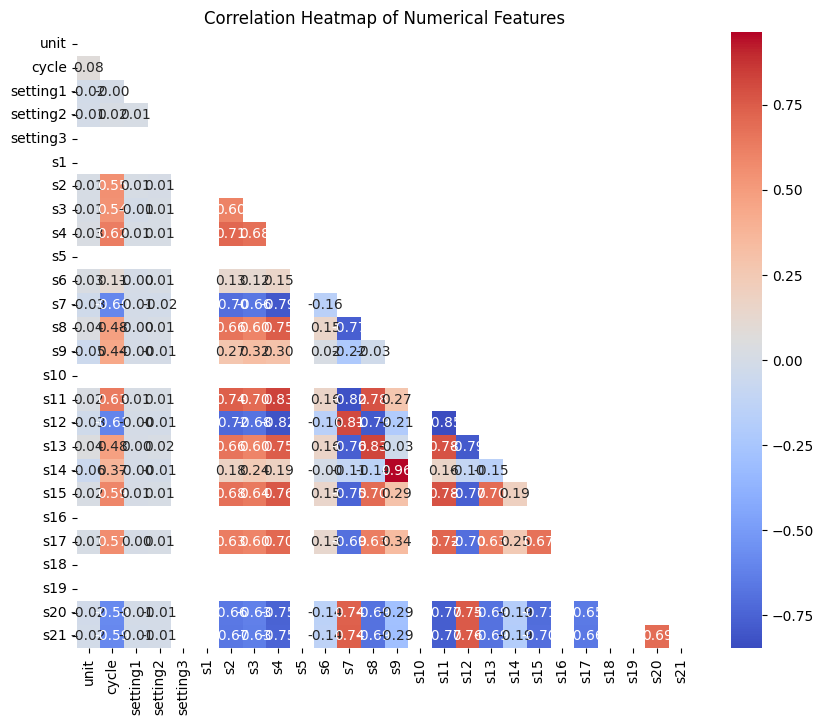

In [ ]:
plt.figure(figsize=(10, 8))
df_filter = df
corr_matrix = df_filter.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix,mask=mask, square=True, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

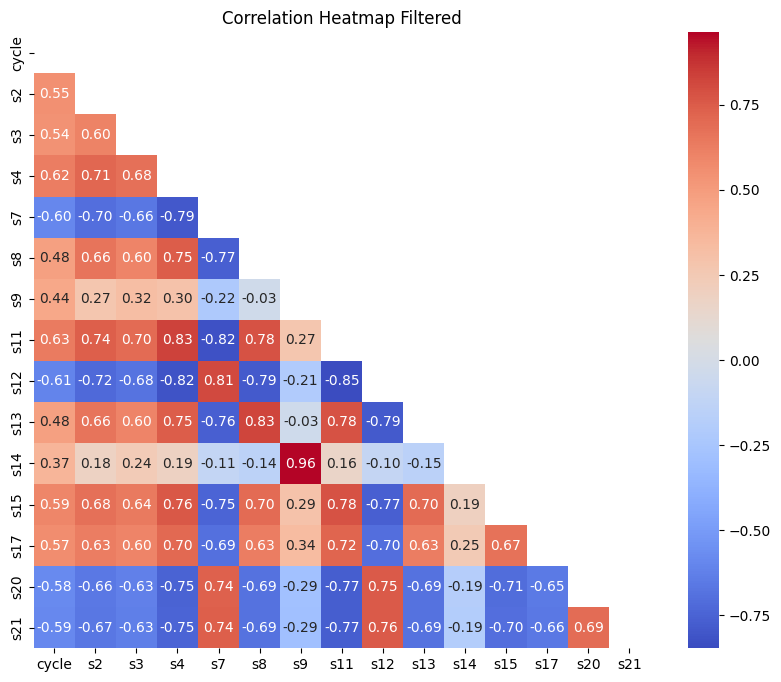

In [ ]:
plt.figure(figsize=(10, 8))
df_filter = df.filter(regex=r'^s\d+|cycle').drop(columns=['s1', 's5', 's6', 's10', 's16', 's18', 's19'], errors='ignore')
corr_matrix = df_filter.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix,mask=mask, square=True, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap Filtered')
plt.show()

### Preprocessing
Remaining Useful Life (RUL)

Threshold 110 for FD001 & 115 for FD003

In [ ]:
MAX_RUL = 110 # Threshold
# Find the maximum cycle achieved by each engine
max_cycles = df.groupby('unit')['cycle'].transform('max')
# Remaining Useful Life (RUL)
df['RUL_raw'] = (max_cycles - df['cycle'])

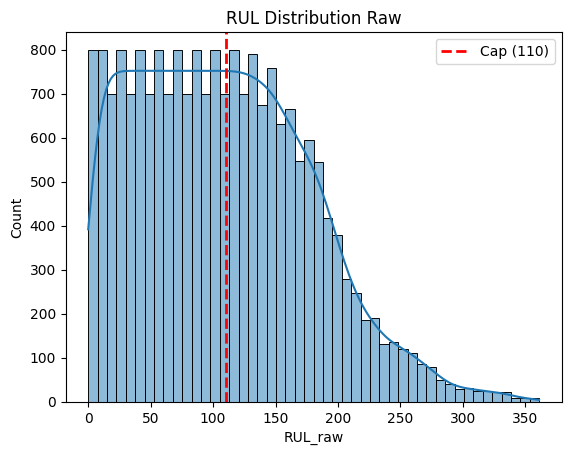

In [ ]:
sns.histplot(df['RUL_raw'], kde=True)
plt.axvline(x=MAX_RUL, color='red', linestyle='--', linewidth=2, label=f'Cap ({MAX_RUL})')
plt.title("RUL Distribution Raw")
plt.legend()
plt.show()

RUL distribution graph provides us the necessary threshold for RUL. Since Early cycle readings show a flat line, This means there is no meaningful change for the model to learn from.

RUL Clipped to a maximum threshold.

In [ ]:
df['RUL'] = df['RUL_raw'].clip(upper=MAX_RUL)

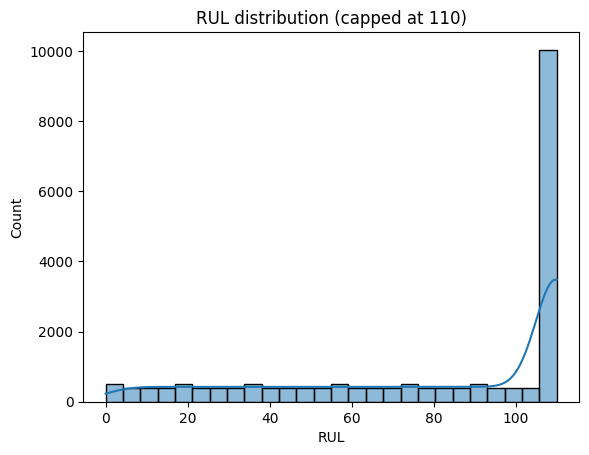

In [ ]:
sns.histplot(df["RUL"], kde=True)
plt.title(f"RUL distribution (capped at {MAX_RUL})")
plt.show()

remove selected columns

In [ ]:
feature_cols = [c for c in df.columns if c not in ["unit", "cycle", "RUL", "RUL_raw"] and not c.startswith("setting")]

prepare dataset for training

In [ ]:
X = df[feature_cols]
y = df["RUL"]
engine_ids = df["unit"]

test_last = test.groupby("unit").tail(1)
X_test = test_last[feature_cols]
y_test = true_rul

Define models

In [ ]:
models = {
    "Ridge": (Ridge(), {"regressor__alpha": [318]}),
    "XGB": (XGBRegressor(), {"regressor__max_depth": [6], "regressor__learning_rate": [0.04]}),
    "LGBM": (LGBMRegressor(verbosity=-1), {"regressor__num_leaves": [17], "regressor__learning_rate": [0.05]}),
    "CatBoost": (CatBoostRegressor(verbose=0), {"regressor__depth": [4], "regressor__learning_rate": [0.02]}),
}

In [ ]:
cv = GroupKFold(n_splits=5)

Metrics Definitions

In [ ]:
def nasa_score(y_true, y_pred):
    d = y_pred - y_true  # positive = predicted too late (worse)
    return np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))

In [ ]:
def plot_importance(pipe, X_eval, y_eval, name):
    pi = permutation_importance(pipe, X_eval, y_eval, n_repeats=30, random_state=0,
                                scoring="neg_root_mean_squared_error")
    imp = pd.DataFrame({"feature": X_eval.columns,
                        "mean": pi.importances_mean,
                        "std": pi.importances_std}).sort_values("mean")
    plt.figure(figsize=(8, 6))
    plt.errorbar(imp["mean"], imp["feature"], xerr=imp["std"], fmt="o",
                 color="black", ecolor="lightgray", elinewidth=5)
    plt.title(f"Permutation importance (all features) - {name}")
    plt.xlabel("Increase in RMSE when feature is shuffled")
    plt.show()

In [ ]:
def shap_explanation(pipeline, X_eval, name):
    final_model = pipeline.named_steps['regressor']
    selected_features = pipeline.named_steps['featsel'].get_feature_names_out(X_eval.columns)

    Xt = pd.DataFrame(
        pipeline[:-1].transform(X_eval),
        columns=selected_features)

    if name == "Ridge":
        explainer = shap.Explainer(final_model.predict, Xt)
    else:
        explainer = shap.TreeExplainer(final_model)

    sv = explainer(Xt)
    shap.summary_plot(sv, Xt, show=False)
    plt.title(f"SHAP summary (selected K features) - {name}")
    plt.tight_layout()
    plt.show()

In [ ]:
def par_dpy(pipeline, X_eval, name, f=0, centered=False):
    try:
        selected_features = pipeline.named_steps['featsel'].get_feature_names_out(X_eval.columns)
        feature = selected_features[f]
        fig, ax = plt.subplots(figsize=(10, 6))
        PartialDependenceDisplay.from_estimator(
            pipeline,
            X_eval,
            features=[feature],
            kind='both',
            pd_line_kw={'color': 'red'},
            ax=ax)
        ax.set_title(f"1D Partial Dependence of {feature} - {name}")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Could not generate Partial Dependence for {name} Model: {e}")

Ignore warnings

In [ ]:
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.utils.validation")

### Prediction Loop

In [ ]:
results_summary = []
fitted, test_preds = {}, {}

In [ ]:
for name, (model, grid)  in models.items():
  print(f"\n================ \033[1m{name}\033[0m =================")
  start_time = t.perf_counter()
  print(f"\n=== Running GridSearch for {name} Model===")
  pipelines = Pipeline([
        ('scaler', StandardScaler()),
        ('featsel', SelectKBest(f_regression, k=14)),
        ('regressor', model)])
  grid_search = GridSearchCV(pipelines, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
  grid_search.fit(X, y, groups=engine_ids)
  best_pipeline = grid_search.best_estimator_
  print(f"\n=== Running Predictions for {name} Model===")
  preds = best_pipeline.predict(X_test)
  print(f"\n=== Getting Results for {name} Model===")
  fitted[name] = best_pipeline
  test_preds[name] = preds
  end_time = t.perf_counter()
  execution_time = end_time - start_time
  results_summary.append({
        "Model": name,
        "Execution Time": execution_time,
        "CV RMSE (all rows)": -grid_search.best_score_,
        "Test RMSE (last cycle)": np.sqrt(mean_squared_error(y_test, preds)),
        "Test MAE": mean_absolute_error(y_test, preds),
        "Test R2": r2_score(y_test, preds),
        "Test NASA score (lower=better)": nasa_score(y_test, preds),
        "Best params": grid_search.best_params_,})


================ Ridge =================

=== Running GridSearch for Ridge Model===

=== Running Predictions for Ridge Model===

=== Getting Results for Ridge Model===

================ XGB =================

=== Running GridSearch for XGB Model===

=== Running Predictions for XGB Model===

=== Getting Results for XGB Model===

================ LGBM =================

=== Running GridSearch for LGBM Model===

=== Running Predictions for LGBM Model===

=== Getting Results for LGBM Model===

================ CatBoost =================

=== Running GridSearch for CatBoost Model===

=== Running Predictions for CatBoost Model===

=== Getting Results for CatBoost Model===


### Results

In [ ]:
df_results = pd.DataFrame(results_summary).set_index('Model')
print("\n=== FINAL LEADERBOARD ===")
print(display(df_results.round(4)))


=== FINAL LEADERBOARD ===


,Execution Time,CV RMSE (all rows),Test RMSE (last cycle),Test MAE,Test R2,Test NASA score (lower=better),Best params
Model,,,,,,,
Ridge,1.8976,18.1741,22.7028,18.6969,0.7015,1046.8242,{'regressor__alpha': 318}
XGB,2.7044,14.9529,18.5218,13.8551,0.8013,659.6393,"{'regressor__learning_rate': 0.04, 'regressor_..."
LGBM,2.6099,14.9470,18.5412,13.8805,0.8009,691.6610,"{'regressor__learning_rate': 0.05, 'regressor_..."
CatBoost,14.6015,14.8603,18.4606,13.4950,0.8027,687.6423,"{'regressor__depth': 4, 'regressor__learning_r..."


None


LGBM
      true        pred       err
unit                            
1      112  107.477555 -4.522445
2       98  104.663532  6.663532
3       69   60.743994 -8.256006
4       82   86.860623  4.860623
5       91   95.645566  4.645566


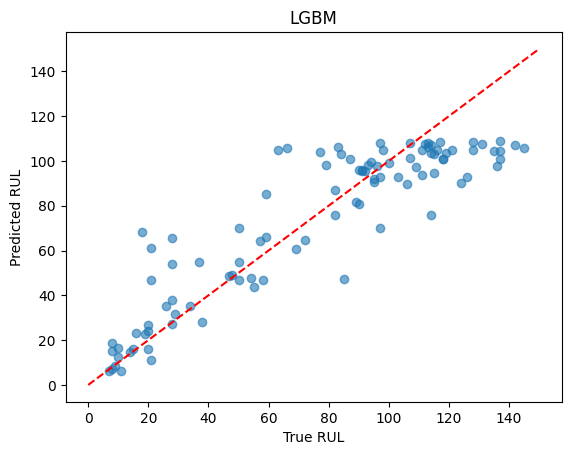

In [ ]:
best = "LGBM"
print(best)
p = test_preds[best]
err = pd.DataFrame({"unit": test_last["unit"].values, "true": true_rul, "pred": p}).set_index("unit")
err["err"] = err["pred"] - err["true"]
print(err.reindex(err["err"].index.sort_values(ascending=True)).head())

plt.scatter(true_rul, p, alpha=0.6)
plt.plot([0, 150], [0, 150], "r--")
plt.xlabel("True RUL"); plt.ylabel("Predicted RUL"); plt.title(best); plt.show()

### Feature Selection & Importance

Best models feature selection


=== Visualization For Feature Selection for LGBM ===


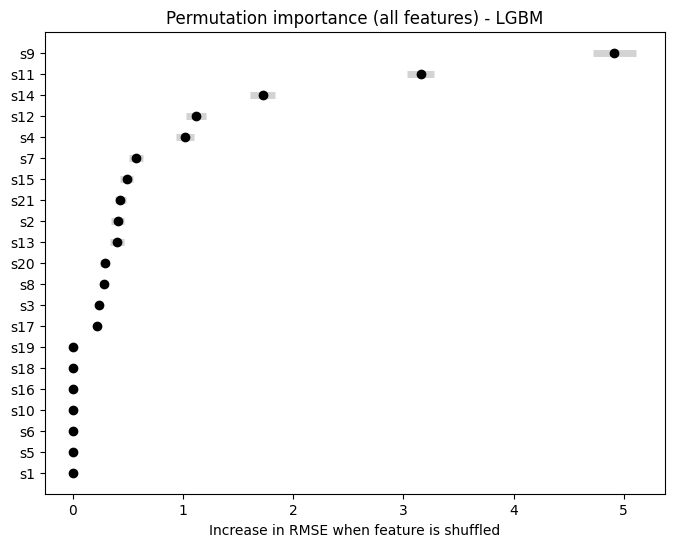

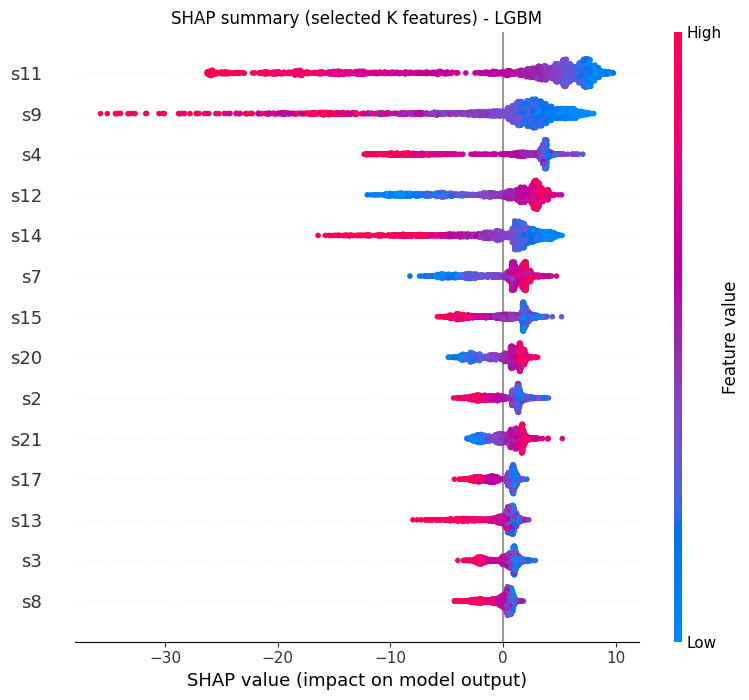


=== Generating Partial Dependence Displays for LGBM ===


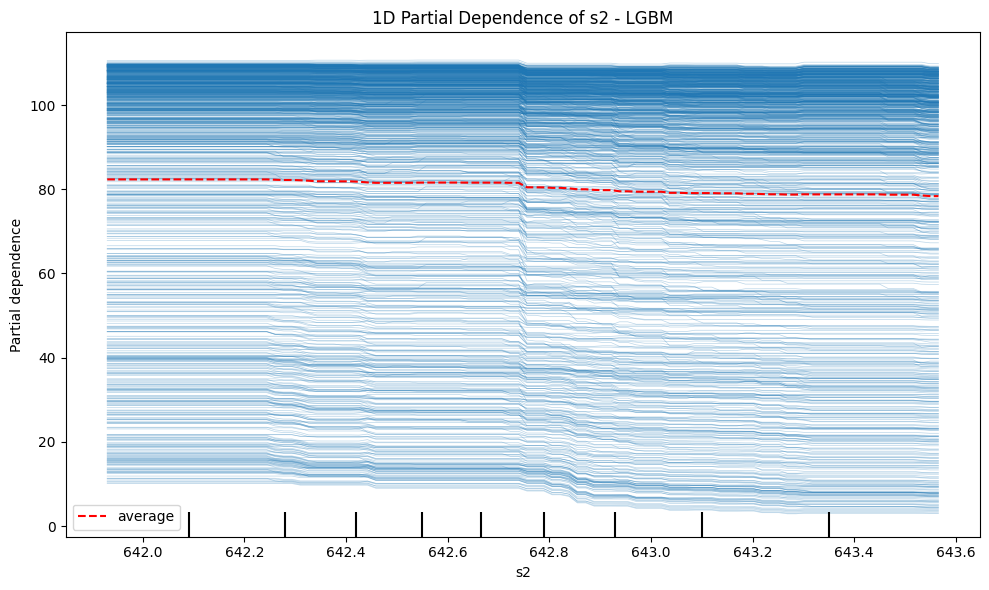

In [ ]:
print(f"\n=== Visualization For Feature Selection for {best} ===")
final = fitted[best]            # best CV model
Xs = X.sample(2000, random_state=0)   # training rows
plot_importance(final, Xs, y.loc[Xs.index], best)
shap_explanation(final, Xs, best)
print(f"\n=== Generating Partial Dependence Displays for {best} ===")
par_dpy(final, Xs, best, f=0)

### Store best Model & Save results

In [ ]:
!mkdir -p $file_v

In [ ]:
joblib.dump({
    "Ridge": fitted["CatBoost"],
    "XGB": fitted["CatBoost"],
    "LGBM": fitted["CatBoost"],
    "CatBoost": fitted["CatBoost"],
    "feature": feature_cols,
}, f"{file_v}/model.joblib")

units = test["unit"].unique()
test[test["unit"].isin(units)].to_csv(f"{file_v}/demo_test.csv", index=False)

pd.DataFrame({
    "unit": np.arange(1, len(true_rul) + 1),
    "true_rul": true_rul
}).to_csv(f"{file_v}/demo_rul.csv", index=False)

df_results.to_csv(f"{file_v}/results.csv", index=True)
print("Demo assets successfully exported!")

Demo assets successfully exported!
